# Thí nghiệm 3: Mức độ ổn định và phân bố kết quả của Genetic Algorithm

**Đề tài 6, nhóm 9 — UEH.** Trưởng nhóm Trương Thành Đạt phụ trách GA; ba thành viên còn lại phụ trách EHO. Notebook này chỉ thực nghiệm Genetic Algorithm (thuật toán di truyền). EHO chưa được triển khai; GUI GA đã có nhưng không tham gia đo thời gian ở đây.

**Cách chạy:** từ root dự án cài `python -m pip install -r requirements.txt`, mở Jupyter hoặc VS Code, chọn interpreter `.venv`, rồi **Restart Kernel & Run All**. Có thể mở từ root hoặc thư mục `Experiment/`. Nếu import lỗi, kiểm tra kernel và cài package bằng interpreter đó; không chỉnh `sys.path`.

Giữ `MODE = 'QUICK'` cho lần đầu. Chế độ này sử dụng năm seed `[11, 23, 37, 53, 71]`; seed là số khởi tạo bộ sinh ngẫu nhiên, giúp chạy lại cùng một phép thử. Đổi sang `FULL` rồi khởi động lại kernel để dùng 25 seed `[101, ..., 125]`. Đây là hai tập khác nhau, không gộp chúng thành một mẫu. Mọi lần chạy có số thế hệ hữu hạn và các nhóm so sánh cùng số phép tính còn có giới hạn evaluations. Notebook không tự chạy lại để tìm một kết quả mong muốn và không xuất file kết quả vào repository.

Chúng tôi đã đọc ba notebook tham chiếu từ Git history `5d81c76` của source được đưa vào dự án, có nguồn [repository đàn anh](https://github.com/ThienNguyen3001/Travelling-Salesman-Genetic-AI-Final). Bản mới giữ thứ tự giới thiệu trường hợp, chạy, vẽ và nhận xét; toàn bộ code gọi package GA hiện tại. Các kết luận, ảnh và số liệu cũ không được dùng lại làm kết quả mới. Không sử dụng các toán tử Single-Point, Two-Point hoặc Uniform Crossover của bản cũ.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from collections import Counter
from math import fsum, isclose
import platform
import statistics
from time import perf_counter

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython import get_ipython
from IPython.display import display, Markdown

from ga_eho_tsp import __version__
from ga_eho_tsp.algorithms.ga import solve
from ga_eho_tsp.data.matrix_loader import load_matrix
from ga_eho_tsp.domain.models import GAConfig
from ga_eho_tsp.domain.objective import validate_route

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 95, 'font.size': 10})
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'pyproject.toml').is_file() and (p / 'data').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Hãy mở notebook từ root dự án hoặc Experiment/ sau khi cài package.')

MODE = 'QUICK'  # Đổi thành 'FULL', sau đó Restart Kernel & Run All.
if MODE not in {'QUICK', 'FULL'}:
    raise ValueError('MODE chỉ nhận QUICK hoặc FULL.')
SEEDS = [11, 23, 37, 53, 71] if MODE == 'QUICK' else list(range(101, 126))
MAX_RUNS = 200 if MODE == 'QUICK' else 1000
TOTAL_SOLVER_LIMIT = 180.0 if MODE == 'QUICK' else 900.0
RUN_COUNT, SOLVER_SECONDS = 0, 0.0
SESSION_START = perf_counter()
print(f'Python {platform.python_version()} | GA {__version__} | chế độ {MODE}')
print(f'Seed: {SEEDS}; tối đa {MAX_RUNS} lần gọi GA; tổng thời gian solver tối đa {TOTAL_SOLVER_LIMIT:g} giây.')

Python 3.11.9 | GA 0.2.0 | chế độ QUICK
Seed: [11, 23, 37, 53, 71]; tối đa 200 lần gọi GA; tổng thời gian solver tối đa 180 giây.


### Quy ước đọc số liệu và các hàm hỗ trợ

Một **lần đánh giá lời giải (evaluation)** là một lần chương trình tính độ dài toàn bộ tuyến đường. Hai cá thể tốt nhất được giữ lại qua thế hệ không cần tính lại chi phí. Khi tắt tìm kiếm cục bộ và hoàn tất G thế hệ, số evaluations bằng `P + G × (P − 2)`, với P là kích thước quần thể và hai cá thể được giữ lại. Vì vậy, cùng số thế hệ chưa có nghĩa là cùng khối lượng tính toán.

**Độ lệch chuẩn** được tính từ các kết quả của tất cả seed, với mẫu số là số lần chạy trừ một. Nó cho biết kết quả phân tán nhiều hay ít quanh trung bình; giá trị nhỏ không tự chứng minh lời giải gần tối ưu. Thời gian đo trong solver, không bao gồm đọc dữ liệu hoặc vẽ hình, và vẫn phụ thuộc máy đang sử dụng.

Những hàm ngắn dưới đây chỉ kiểm tra, tổng hợp và vẽ kết quả; chúng không cài đặt lại GA. Mỗi tour được kiểm tra là hoán vị đủ thành phố, bắt đầu ở0, và tính lại chi phí trực tiếp từ ma trận, bao gồm cạnh quay về đầu. Nếu một lần chạy lỗi, notebook dừng và nêu lỗi, không bỏ kết quả đó để tính trung bình. Nếu dừng sớm vì thời gian hoặc trì trệ, kết quả hợp lệ vẫn được giữ và trạng thái được liệt kê trong bảng.

Trong bảng cấu hình, cột **Thế hệ G/M** lần lượt là `generations` và `max_iterations`; số vòng tối đa thực sự là giá trị nhỏ hơn trong hai số. Trong bảng kết quả, **Đánh giá min–max** và **Thế hệ TB** là số đã thực hiện, không phải giới hạn đã nhập. Mọi đường hội tụ dùng lời giải tốt nhất từ đầu đến thời điểm đó (`best_so_far`), nên không tăng khi thuật toán tìm được lời giải mới.

Các mã trong cột lý do dừng có ý nghĩa như sau: `MAX_ITERATIONS` là hết số thế hệ cho phép; `MAX_EVALUATIONS` là đã dùng hết số lần đánh giá; `TIME_LIMIT` là hết thời gian được cấp; `STAGNATION` là đạt số thế hệ không cải thiện đã đặt; `CANCELLED` là có yêu cầu hủy. Chúng mô tả cách lần chạy kết thúc, không xác nhận đã tìm được nghiệm tối ưu.

In [2]:
def show_table(headers, rows):
    text = '| ' + ' | '.join(headers) + ' |\n'
    text += '| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
    text += '\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in rows)
    display(Markdown(text))


def checked_solve(problem, config):
    global RUN_COUNT, SOLVER_SECONDS
    if RUN_COUNT >= MAX_RUNS or SOLVER_SECONDS >= TOTAL_SOLVER_LIMIT:
        raise RuntimeError('Vượt giới hạn notebook; batch chưa hoàn tất, không được báo thành công.')
    result = solve(problem, config)
    RUN_COUNT += 1
    SOLVER_SECONDS += result.elapsed_seconds
    validate_route(result.best_route, problem.dimension)
    route = result.best_route
    cost = fsum(problem.distance_matrix[route[i]][route[(i + 1) % len(route)]]
                for i in range(len(route)))
    assert result.is_valid and isclose(cost, result.best_distance, abs_tol=1e-9, rel_tol=1e-12)
    assert result.config_snapshot == asdict(config)
    assert result.iterations_completed <= min(config.generations, config.max_iterations)
    if config.max_evaluations is not None:
        assert result.evaluations <= config.max_evaluations
    assert result.history[0].iteration == 0
    assert result.history[0].evaluations == config.population_size
    assert result.history[-1].evaluations == result.evaluations
    assert result.history[-1].best_so_far == result.best_distance
    assert all(b.best_so_far <= a.best_so_far and b.evaluations >= a.evaluations
               for a, b in zip(result.history, result.history[1:]))
    assert result.metadata['local_search_full_evaluations'] <= result.evaluations
    if not config.local_search_enabled and result.stopping_reason == 'MAX_ITERATIONS':
        assert result.evaluations == config.population_size + result.iterations_completed * (
            config.population_size - config.elite_count)
    return result


def summarize(runs):
    assert len(runs) == len(SEEDS) and [r.seed for r in runs] == SEEDS
    distances = [r.best_distance for r in runs]
    return dict(mean=statistics.mean(distances), std=statistics.stdev(distances),
                best=min(distances), worst=max(distances), median=statistics.median(distances),
                eval_min=min(r.evaluations for r in runs), eval_max=max(r.evaluations for r in runs),
                eval_mean=statistics.mean(r.evaluations for r in runs),
                generations=statistics.mean(r.iterations_completed for r in runs),
                seconds=statistics.mean(r.elapsed_seconds for r in runs),
                initial_mean=statistics.mean(r.history[0].best_so_far for r in runs),
                local_calls=statistics.mean(r.metadata['local_search_full_evaluations'] for r in runs),
                reasons=dict(Counter(r.stopping_reason for r in runs)))


def numeric_signature(result):
    return (result.best_route, result.best_distance, result.evaluations, result.iterations_completed,
            result.stopping_reason, result.config_snapshot,
            tuple((s.iteration, s.best_current, s.best_so_far, s.mean_fitness,
                   s.evaluations, s.population_diversity) for s in result.history))

## Vì sao cần chạy nhiều lần?

GA có ngẫu nhiên trong khởi tạo, chọn bố mẹ và biến đổi tour. Với các seed khác nhau, kết quả có thể khác nhau; chỉ trình bày một tour ngắn sẽ không cho biết thuật toán ổn định đến đâu. Chúng tôi giữ cách khảo sát theo từng bộ dữ liệu của notebook tham chiếu nhưng dùng 5 seed ở QUICK và 25 seed ở FULL thay cho 1000 lần chạy. Chúng tôi duy trì 40 cá thể trong quần thể, sử dụng Tournament Selection (chọn bố mẹ bằng thi đấu giữa ba ứng viên), Order Crossover — OX (lai ghép theo thứ tự với xác suất 90%) và Inversion Mutation (đột biến đảo đoạn với xác suất 15% trên cả tour) và giữ hai cá thể tốt nhất sang thế hệ mới (Elitism); quần thể ban đầu được tạo ngẫu nhiên, mỗi lần tối đa 4000 evaluations ở QUICK hoặc 12000 ở FULL. Việc tăng evaluations trong FULL được công bố cùng seed; không gộp QUICK và FULL như cùng điều kiện.

**Mốc đối chiếu cần được xác minh.** Nếu `known_optimum` có giá trị đã kiểm chứng, chênh lệch so với nó phản ánh khoảng cách tới nghiệm tối ưu. Với các file hiện tại trường này là None. Chúng tôi chỉ liệt kê các tour của bài 3/4/6 thành phố để kiểm chứng độc lập giá trị nhỏ nhất; không đưa thêm solver vào thư viện. Với bài lớn, dùng tour ngắn nhất trong toàn bộ mẫu đang chạy làm mốc. Chênh lệch này chỉ đo khoảng cách tới kết quả tốt nhất quan sát được, không phải sai số tối ưu.

Trên histogram, trục ngang là độ dài hoặc chênh lệch đã định nghĩa, trục dọc là số lần xuất hiện. Nhiều kết quả gần nhau cho thấy phân tán nhỏ trong mẫu; nếu tất cả bằng nhau, chúng tôi vẽ một cột tại đúng giá trị đó, không thêm điểm giả. Mỗi dataset có thang độ dài riêng. Độ lệch chuẩn của bài 48 thành phố lớn hơn về số tuyệt đối chưa đủ để kết luận kém ổn định hơn bài nhỏ vì thang chi phí khác nhau.

In [3]:
from itertools import permutations

EVALUATIONS = 4000 if MODE == 'QUICK' else 12000
BASE = replace(GAConfig(), population_size=40, generations=4000, max_iterations=4000,
               max_evaluations=EVALUATIONS, time_limit_seconds=10.0)
DATASETS = ['03Cities-6.txt', '04Cities-189.txt', '06Cities-1248.txt', '15Cities-1194.txt',
            '26Cities-937.txt', '42Cities-699.txt', '48Cities-33523.txt']
runs_by_dataset, distribution_summary, references = {}, {}, {}
show_table(['Quần thể', 'Tỷ lệ đột biến', 'Giới hạn thế hệ G/M', 'Evaluations tối đa mỗi run'],
           [[BASE.population_size, BASE.mutation_rate, f'{BASE.generations}/{BASE.max_iterations}', EVALUATIONS]])


def frequency_plot(ax, values, xlabel, title):
    if len(set(values)) == 1:
        value = values[0]
        ax.bar([value], [len(values)], width=max(0.5, abs(value) * .002), color='#42849c')
        ax.set_xticks([value])
    else:
        counts, _, _ = ax.hist(values, bins=min(8, len(values)), color='#42849c', edgecolor='white')
        assert sum(counts) == len(values)
    ax.set(xlabel=xlabel, ylabel='Số lần xuất hiện', title=title, ylim=(0, len(values) + 1))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

| Quần thể | Tỷ lệ đột biến | Giới hạn thế hệ G/M | Evaluations tối đa mỗi run |
| --- | --- | --- | --- |
| 40 | 0.15 | 4000/4000 | 4000 |

### Trường hợp 3 thành phố

Ma trận `03Cities-6.txt` có 3 hàng và 3 cột, mô tả chi phí giữa các thành phố. Chúng tôi chạy cùng cấu hình đã công bố và giữ tất cả seed để xem kết quả có tập trung hay phân tán. Vì bài rất nhỏ, mốc tối ưu được kiểm chứng bằng cách liệt kê đầy đủ tour bắt đầu ở0 và tính đủ cạnh quay về 0.

Bảng cho biết tốt nhất, trung bình, kém nhất, độ lệch chuẩn và số đánh giá thực tế. Hai hình đặt cạnh nhau lần lượt là phân bố độ dài và phân bố chênh lệch so với mốc được ghi trong tiêu đề. Giá trị 0 ở hình bên phải có nghĩa là bằng mốc đó; chỉ với mốc tối ưu đã kiểm chứng mới được hiểu là đạt tối ưu. Nhận xét sau hình dùng kết quả của toàn bộ seed, không dựa vào run riêng lẻ.

| Số lần | Tốt nhất | Trung bình | Kém nhất | Độ lệch chuẩn | Đánh giá min–max | Thời gian TB (s) |
| --- | --- | --- | --- | --- | --- | --- |
| 5 | 6 | 6.00 | 6 | 0.00 | 4000–4000 | 0.0421 |

Mốc: Tối ưu kiểm chứng bằng liệt kê = 6.0 | Trạng thái: {'MAX_EVALUATIONS': 5}


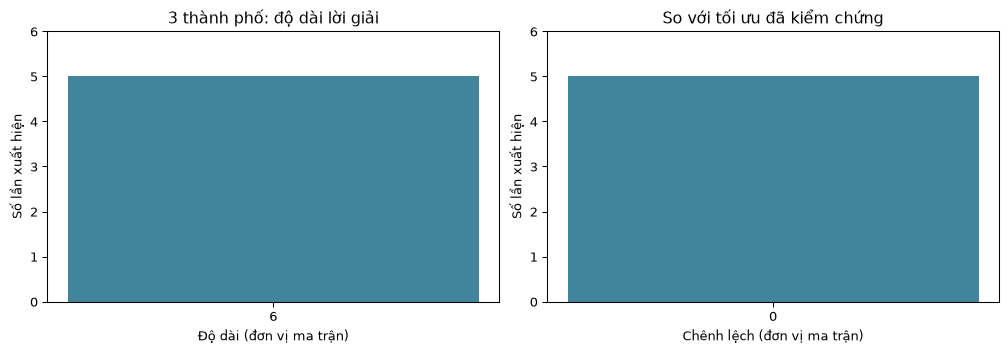

In [4]:
problem = load_matrix(ROOT/'data'/'03Cities-6.txt')
runs = [checked_solve(problem, replace(BASE, seed=seed)) for seed in SEEDS]
runs_by_dataset[problem.name] = runs
summary = summarize(runs)
if problem.known_optimum is not None:
    reference, reference_label = problem.known_optimum, 'Nghiệm tối ưu đã xác minh từ dữ liệu'
elif problem.dimension <= 6:
    n, matrix = problem.dimension, problem.distance_matrix
    reference = min(fsum(matrix[route[i]][route[(i + 1) % n]] for i in range(n))
                    for tail in permutations(range(1, n)) for route in [(0, *tail)])
    reference_label = 'Tối ưu kiểm chứng bằng liệt kê'
else:
    reference, reference_label = summary['best'], 'Tốt nhất quan sát trong mẫu'
deviations = [r.best_distance - reference for r in runs]
assert all(value >= -1e-9 for value in deviations)
summary.update(n=problem.dimension, reference=reference, reference_label=reference_label,
               deviation_mean=statistics.mean(deviations),
               relative_deviation=100 * statistics.mean(deviations) / reference if reference > 0 else None)
distribution_summary[problem.name] = summary
references[problem.name] = dict(value=reference, source=reference_label)
show_table(['Số lần', 'Tốt nhất', 'Trung bình', 'Kém nhất', 'Độ lệch chuẩn', 'Đánh giá min–max', 'Thời gian TB (s)'],
           [[len(runs), f"{summary['best']:g}", f"{summary['mean']:.2f}", f"{summary['worst']:g}",
             f"{summary['std']:.2f}", f"{summary['eval_min']}–{summary['eval_max']}", f"{summary['seconds']:.4f}"]])
print('Mốc:', reference_label, '=', reference, '| Trạng thái:', summary['reasons'])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), layout='constrained')
frequency_plot(axes[0], [r.best_distance for r in runs], 'Độ dài (đơn vị ma trận)', '3 thành phố: độ dài lời giải')
frequency_plot(axes[1], deviations, 'Chênh lệch (đơn vị ma trận)', 'So với tốt nhất trong mẫu' if reference_label == 'Tốt nhất quan sát trong mẫu' else 'So với tối ưu đã kiểm chứng')
plt.show(); plt.close(fig)

In [5]:
same_count = sum(isclose(r.best_distance, reference, abs_tol=1e-9) for r in runs)
spread_text = ('Các lần chạy cho cùng độ dài trong mẫu này.' if summary['std'] == 0 else
               'Các lần chạy có độ dài khác nhau, nên một lời giải riêng lẻ không mô tả đủ kết quả.')
display(Markdown(f"**Nhận xét.** Bài {problem.dimension} thành phố có độ dài từ {summary['best']:g} "
    f"đến {summary['worst']:g}, trung bình {summary['mean']:.2f}, độ lệch chuẩn {summary['std']:.2f}. "
    + spread_text + f" Chênh lệch trung bình so với mốc **{reference_label.lower()}** là "
    f"{summary['deviation_mean']:.2f}; có {same_count}/{len(runs)} lần bằng mốc. "
    + ('Với bài nhỏ đã liệt kê, đây là đối chiếu với nghiệm tối ưu của đúng ma trận đang dùng. '
       if 'liệt kê' in reference_label else
       'Với mốc tốt nhất quan sát, số lần bằng mốc không phải xác suất tìm nghiệm tối ưu. '
       if reference_label == 'Tốt nhất quan sát trong mẫu' else
       'Kết quả dùng nguồn optimum được gắn trong TSPProblem. ')
    + 'Các seed đã khai báo được giữ đầy đủ; mẫu ít không đủ để suy ra mức ổn định trên mọi bài toán.'))

**Nhận xét.** Bài 3 thành phố có độ dài từ 6 đến 6, trung bình 6.00, độ lệch chuẩn 0.00. Các lần chạy cho cùng độ dài trong mẫu này. Chênh lệch trung bình so với mốc **tối ưu kiểm chứng bằng liệt kê** là 0.00; có 5/5 lần bằng mốc. Với bài nhỏ đã liệt kê, đây là đối chiếu với nghiệm tối ưu của đúng ma trận đang dùng. Các seed đã khai báo được giữ đầy đủ; mẫu ít không đủ để suy ra mức ổn định trên mọi bài toán.

### Trường hợp 4 thành phố

Ma trận `04Cities-189.txt` có 4 hàng và 4 cột, mô tả chi phí giữa các thành phố. Chúng tôi chạy cùng cấu hình đã công bố và giữ tất cả seed để xem kết quả có tập trung hay phân tán. Vì bài rất nhỏ, mốc tối ưu được kiểm chứng bằng cách liệt kê đầy đủ tour bắt đầu ở0 và tính đủ cạnh quay về 0.

Bảng cho biết tốt nhất, trung bình, kém nhất, độ lệch chuẩn và số đánh giá thực tế. Hai hình đặt cạnh nhau lần lượt là phân bố độ dài và phân bố chênh lệch so với mốc được ghi trong tiêu đề. Giá trị 0 ở hình bên phải có nghĩa là bằng mốc đó; chỉ với mốc tối ưu đã kiểm chứng mới được hiểu là đạt tối ưu. Nhận xét sau hình dùng kết quả của toàn bộ seed, không dựa vào run riêng lẻ.

| Số lần | Tốt nhất | Trung bình | Kém nhất | Độ lệch chuẩn | Đánh giá min–max | Thời gian TB (s) |
| --- | --- | --- | --- | --- | --- | --- |
| 5 | 189 | 189.00 | 189 | 0.00 | 4000–4000 | 0.0415 |

Mốc: Tối ưu kiểm chứng bằng liệt kê = 189.0 | Trạng thái: {'MAX_EVALUATIONS': 5}


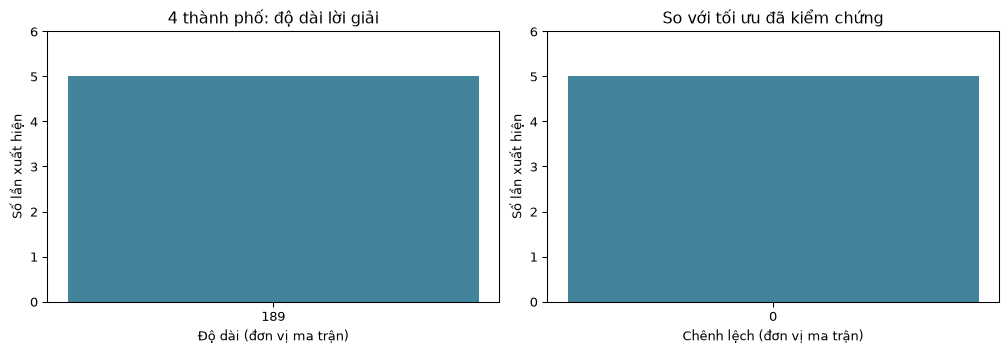

In [6]:
problem = load_matrix(ROOT/'data'/'04Cities-189.txt')
runs = [checked_solve(problem, replace(BASE, seed=seed)) for seed in SEEDS]
runs_by_dataset[problem.name] = runs
summary = summarize(runs)
if problem.known_optimum is not None:
    reference, reference_label = problem.known_optimum, 'Nghiệm tối ưu đã xác minh từ dữ liệu'
elif problem.dimension <= 6:
    n, matrix = problem.dimension, problem.distance_matrix
    reference = min(fsum(matrix[route[i]][route[(i + 1) % n]] for i in range(n))
                    for tail in permutations(range(1, n)) for route in [(0, *tail)])
    reference_label = 'Tối ưu kiểm chứng bằng liệt kê'
else:
    reference, reference_label = summary['best'], 'Tốt nhất quan sát trong mẫu'
deviations = [r.best_distance - reference for r in runs]
assert all(value >= -1e-9 for value in deviations)
summary.update(n=problem.dimension, reference=reference, reference_label=reference_label,
               deviation_mean=statistics.mean(deviations),
               relative_deviation=100 * statistics.mean(deviations) / reference if reference > 0 else None)
distribution_summary[problem.name] = summary
references[problem.name] = dict(value=reference, source=reference_label)
show_table(['Số lần', 'Tốt nhất', 'Trung bình', 'Kém nhất', 'Độ lệch chuẩn', 'Đánh giá min–max', 'Thời gian TB (s)'],
           [[len(runs), f"{summary['best']:g}", f"{summary['mean']:.2f}", f"{summary['worst']:g}",
             f"{summary['std']:.2f}", f"{summary['eval_min']}–{summary['eval_max']}", f"{summary['seconds']:.4f}"]])
print('Mốc:', reference_label, '=', reference, '| Trạng thái:', summary['reasons'])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), layout='constrained')
frequency_plot(axes[0], [r.best_distance for r in runs], 'Độ dài (đơn vị ma trận)', '4 thành phố: độ dài lời giải')
frequency_plot(axes[1], deviations, 'Chênh lệch (đơn vị ma trận)', 'So với tốt nhất trong mẫu' if reference_label == 'Tốt nhất quan sát trong mẫu' else 'So với tối ưu đã kiểm chứng')
plt.show(); plt.close(fig)

In [7]:
same_count = sum(isclose(r.best_distance, reference, abs_tol=1e-9) for r in runs)
spread_text = ('Các lần chạy cho cùng độ dài trong mẫu này.' if summary['std'] == 0 else
               'Các lần chạy có độ dài khác nhau, nên một lời giải riêng lẻ không mô tả đủ kết quả.')
display(Markdown(f"**Nhận xét.** Bài {problem.dimension} thành phố có độ dài từ {summary['best']:g} "
    f"đến {summary['worst']:g}, trung bình {summary['mean']:.2f}, độ lệch chuẩn {summary['std']:.2f}. "
    + spread_text + f" Chênh lệch trung bình so với mốc **{reference_label.lower()}** là "
    f"{summary['deviation_mean']:.2f}; có {same_count}/{len(runs)} lần bằng mốc. "
    + ('Với bài nhỏ đã liệt kê, đây là đối chiếu với nghiệm tối ưu của đúng ma trận đang dùng. '
       if 'liệt kê' in reference_label else
       'Với mốc tốt nhất quan sát, số lần bằng mốc không phải xác suất tìm nghiệm tối ưu. '
       if reference_label == 'Tốt nhất quan sát trong mẫu' else
       'Kết quả dùng nguồn optimum được gắn trong TSPProblem. ')
    + 'Các seed đã khai báo được giữ đầy đủ; mẫu ít không đủ để suy ra mức ổn định trên mọi bài toán.'))

**Nhận xét.** Bài 4 thành phố có độ dài từ 189 đến 189, trung bình 189.00, độ lệch chuẩn 0.00. Các lần chạy cho cùng độ dài trong mẫu này. Chênh lệch trung bình so với mốc **tối ưu kiểm chứng bằng liệt kê** là 0.00; có 5/5 lần bằng mốc. Với bài nhỏ đã liệt kê, đây là đối chiếu với nghiệm tối ưu của đúng ma trận đang dùng. Các seed đã khai báo được giữ đầy đủ; mẫu ít không đủ để suy ra mức ổn định trên mọi bài toán.

### Trường hợp 6 thành phố

Ma trận `06Cities-1248.txt` có 6 hàng và 6 cột, mô tả chi phí giữa các thành phố. Chúng tôi chạy cùng cấu hình đã công bố và giữ tất cả seed để xem kết quả có tập trung hay phân tán. Vì bài rất nhỏ, mốc tối ưu được kiểm chứng bằng cách liệt kê đầy đủ tour bắt đầu ở0 và tính đủ cạnh quay về 0.

Bảng cho biết tốt nhất, trung bình, kém nhất, độ lệch chuẩn và số đánh giá thực tế. Hai hình đặt cạnh nhau lần lượt là phân bố độ dài và phân bố chênh lệch so với mốc được ghi trong tiêu đề. Giá trị 0 ở hình bên phải có nghĩa là bằng mốc đó; chỉ với mốc tối ưu đã kiểm chứng mới được hiểu là đạt tối ưu. Nhận xét sau hình dùng kết quả của toàn bộ seed, không dựa vào run riêng lẻ.

| Số lần | Tốt nhất | Trung bình | Kém nhất | Độ lệch chuẩn | Đánh giá min–max | Thời gian TB (s) |
| --- | --- | --- | --- | --- | --- | --- |
| 5 | 1248 | 1248.00 | 1248 | 0.00 | 4000–4000 | 0.0476 |

Mốc: Tối ưu kiểm chứng bằng liệt kê = 1248.0 | Trạng thái: {'MAX_EVALUATIONS': 5}


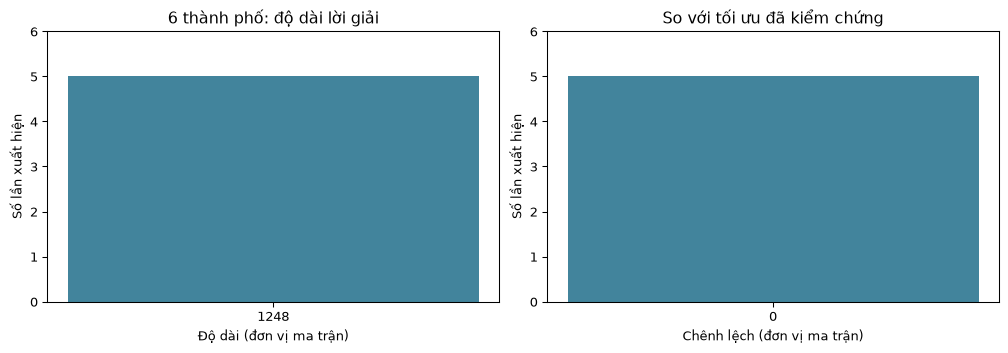

In [8]:
problem = load_matrix(ROOT/'data'/'06Cities-1248.txt')
runs = [checked_solve(problem, replace(BASE, seed=seed)) for seed in SEEDS]
runs_by_dataset[problem.name] = runs
summary = summarize(runs)
if problem.known_optimum is not None:
    reference, reference_label = problem.known_optimum, 'Nghiệm tối ưu đã xác minh từ dữ liệu'
elif problem.dimension <= 6:
    n, matrix = problem.dimension, problem.distance_matrix
    reference = min(fsum(matrix[route[i]][route[(i + 1) % n]] for i in range(n))
                    for tail in permutations(range(1, n)) for route in [(0, *tail)])
    reference_label = 'Tối ưu kiểm chứng bằng liệt kê'
else:
    reference, reference_label = summary['best'], 'Tốt nhất quan sát trong mẫu'
deviations = [r.best_distance - reference for r in runs]
assert all(value >= -1e-9 for value in deviations)
summary.update(n=problem.dimension, reference=reference, reference_label=reference_label,
               deviation_mean=statistics.mean(deviations),
               relative_deviation=100 * statistics.mean(deviations) / reference if reference > 0 else None)
distribution_summary[problem.name] = summary
references[problem.name] = dict(value=reference, source=reference_label)
show_table(['Số lần', 'Tốt nhất', 'Trung bình', 'Kém nhất', 'Độ lệch chuẩn', 'Đánh giá min–max', 'Thời gian TB (s)'],
           [[len(runs), f"{summary['best']:g}", f"{summary['mean']:.2f}", f"{summary['worst']:g}",
             f"{summary['std']:.2f}", f"{summary['eval_min']}–{summary['eval_max']}", f"{summary['seconds']:.4f}"]])
print('Mốc:', reference_label, '=', reference, '| Trạng thái:', summary['reasons'])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), layout='constrained')
frequency_plot(axes[0], [r.best_distance for r in runs], 'Độ dài (đơn vị ma trận)', '6 thành phố: độ dài lời giải')
frequency_plot(axes[1], deviations, 'Chênh lệch (đơn vị ma trận)', 'So với tốt nhất trong mẫu' if reference_label == 'Tốt nhất quan sát trong mẫu' else 'So với tối ưu đã kiểm chứng')
plt.show(); plt.close(fig)

In [9]:
same_count = sum(isclose(r.best_distance, reference, abs_tol=1e-9) for r in runs)
spread_text = ('Các lần chạy cho cùng độ dài trong mẫu này.' if summary['std'] == 0 else
               'Các lần chạy có độ dài khác nhau, nên một lời giải riêng lẻ không mô tả đủ kết quả.')
display(Markdown(f"**Nhận xét.** Bài {problem.dimension} thành phố có độ dài từ {summary['best']:g} "
    f"đến {summary['worst']:g}, trung bình {summary['mean']:.2f}, độ lệch chuẩn {summary['std']:.2f}. "
    + spread_text + f" Chênh lệch trung bình so với mốc **{reference_label.lower()}** là "
    f"{summary['deviation_mean']:.2f}; có {same_count}/{len(runs)} lần bằng mốc. "
    + ('Với bài nhỏ đã liệt kê, đây là đối chiếu với nghiệm tối ưu của đúng ma trận đang dùng. '
       if 'liệt kê' in reference_label else
       'Với mốc tốt nhất quan sát, số lần bằng mốc không phải xác suất tìm nghiệm tối ưu. '
       if reference_label == 'Tốt nhất quan sát trong mẫu' else
       'Kết quả dùng nguồn optimum được gắn trong TSPProblem. ')
    + 'Các seed đã khai báo được giữ đầy đủ; mẫu ít không đủ để suy ra mức ổn định trên mọi bài toán.'))

**Nhận xét.** Bài 6 thành phố có độ dài từ 1248 đến 1248, trung bình 1248.00, độ lệch chuẩn 0.00. Các lần chạy cho cùng độ dài trong mẫu này. Chênh lệch trung bình so với mốc **tối ưu kiểm chứng bằng liệt kê** là 0.00; có 5/5 lần bằng mốc. Với bài nhỏ đã liệt kê, đây là đối chiếu với nghiệm tối ưu của đúng ma trận đang dùng. Các seed đã khai báo được giữ đầy đủ; mẫu ít không đủ để suy ra mức ổn định trên mọi bài toán.

### Trường hợp 15 thành phố

Ma trận `15Cities-1194.txt` có 15 hàng và 15 cột, mô tả chi phí giữa các thành phố. Chúng tôi chạy cùng cấu hình đã công bố và giữ tất cả seed để xem kết quả có tập trung hay phân tán. Với bài này chưa có nghiệm tối ưu được xác minh; mốc sẽ là tour ngắn nhất trong mẫu của chính dataset này, không lấy số trong tên file.

Bảng cho biết tốt nhất, trung bình, kém nhất, độ lệch chuẩn và số đánh giá thực tế. Hai hình đặt cạnh nhau lần lượt là phân bố độ dài và phân bố chênh lệch so với mốc được ghi trong tiêu đề. Giá trị 0 ở hình bên phải có nghĩa là bằng mốc đó; chỉ với mốc tối ưu đã kiểm chứng mới được hiểu là đạt tối ưu. Nhận xét sau hình dùng kết quả của toàn bộ seed, không dựa vào run riêng lẻ.

| Số lần | Tốt nhất | Trung bình | Kém nhất | Độ lệch chuẩn | Đánh giá min–max | Thời gian TB (s) |
| --- | --- | --- | --- | --- | --- | --- |
| 5 | 1194 | 1200.20 | 1225 | 13.86 | 4000–4000 | 0.0980 |

Mốc: Tốt nhất quan sát trong mẫu = 1194.0 | Trạng thái: {'MAX_EVALUATIONS': 5}


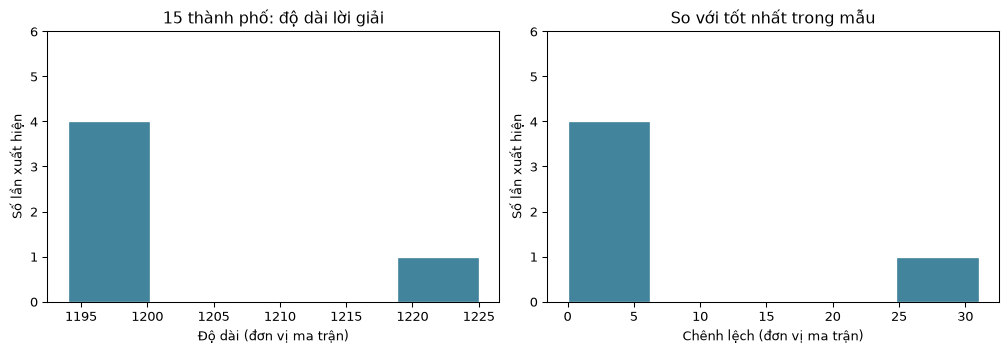

In [10]:
problem = load_matrix(ROOT/'data'/'15Cities-1194.txt')
runs = [checked_solve(problem, replace(BASE, seed=seed)) for seed in SEEDS]
runs_by_dataset[problem.name] = runs
summary = summarize(runs)
if problem.known_optimum is not None:
    reference, reference_label = problem.known_optimum, 'Nghiệm tối ưu đã xác minh từ dữ liệu'
elif problem.dimension <= 6:
    n, matrix = problem.dimension, problem.distance_matrix
    reference = min(fsum(matrix[route[i]][route[(i + 1) % n]] for i in range(n))
                    for tail in permutations(range(1, n)) for route in [(0, *tail)])
    reference_label = 'Tối ưu kiểm chứng bằng liệt kê'
else:
    reference, reference_label = summary['best'], 'Tốt nhất quan sát trong mẫu'
deviations = [r.best_distance - reference for r in runs]
assert all(value >= -1e-9 for value in deviations)
summary.update(n=problem.dimension, reference=reference, reference_label=reference_label,
               deviation_mean=statistics.mean(deviations),
               relative_deviation=100 * statistics.mean(deviations) / reference if reference > 0 else None)
distribution_summary[problem.name] = summary
references[problem.name] = dict(value=reference, source=reference_label)
show_table(['Số lần', 'Tốt nhất', 'Trung bình', 'Kém nhất', 'Độ lệch chuẩn', 'Đánh giá min–max', 'Thời gian TB (s)'],
           [[len(runs), f"{summary['best']:g}", f"{summary['mean']:.2f}", f"{summary['worst']:g}",
             f"{summary['std']:.2f}", f"{summary['eval_min']}–{summary['eval_max']}", f"{summary['seconds']:.4f}"]])
print('Mốc:', reference_label, '=', reference, '| Trạng thái:', summary['reasons'])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), layout='constrained')
frequency_plot(axes[0], [r.best_distance for r in runs], 'Độ dài (đơn vị ma trận)', '15 thành phố: độ dài lời giải')
frequency_plot(axes[1], deviations, 'Chênh lệch (đơn vị ma trận)', 'So với tốt nhất trong mẫu' if reference_label == 'Tốt nhất quan sát trong mẫu' else 'So với tối ưu đã kiểm chứng')
plt.show(); plt.close(fig)

In [11]:
same_count = sum(isclose(r.best_distance, reference, abs_tol=1e-9) for r in runs)
spread_text = ('Các lần chạy cho cùng độ dài trong mẫu này.' if summary['std'] == 0 else
               'Các lần chạy có độ dài khác nhau, nên một lời giải riêng lẻ không mô tả đủ kết quả.')
display(Markdown(f"**Nhận xét.** Bài {problem.dimension} thành phố có độ dài từ {summary['best']:g} "
    f"đến {summary['worst']:g}, trung bình {summary['mean']:.2f}, độ lệch chuẩn {summary['std']:.2f}. "
    + spread_text + f" Chênh lệch trung bình so với mốc **{reference_label.lower()}** là "
    f"{summary['deviation_mean']:.2f}; có {same_count}/{len(runs)} lần bằng mốc. "
    + ('Với bài nhỏ đã liệt kê, đây là đối chiếu với nghiệm tối ưu của đúng ma trận đang dùng. '
       if 'liệt kê' in reference_label else
       'Với mốc tốt nhất quan sát, số lần bằng mốc không phải xác suất tìm nghiệm tối ưu. '
       if reference_label == 'Tốt nhất quan sát trong mẫu' else
       'Kết quả dùng nguồn optimum được gắn trong TSPProblem. ')
    + 'Các seed đã khai báo được giữ đầy đủ; mẫu ít không đủ để suy ra mức ổn định trên mọi bài toán.'))

**Nhận xét.** Bài 15 thành phố có độ dài từ 1194 đến 1225, trung bình 1200.20, độ lệch chuẩn 13.86. Các lần chạy có độ dài khác nhau, nên một lời giải riêng lẻ không mô tả đủ kết quả. Chênh lệch trung bình so với mốc **tốt nhất quan sát trong mẫu** là 6.20; có 4/5 lần bằng mốc. Với mốc tốt nhất quan sát, số lần bằng mốc không phải xác suất tìm nghiệm tối ưu. Các seed đã khai báo được giữ đầy đủ; mẫu ít không đủ để suy ra mức ổn định trên mọi bài toán.

### Trường hợp 26 thành phố

Ma trận `26Cities-937.txt` có 26 hàng và 26 cột, mô tả chi phí giữa các thành phố. Chúng tôi chạy cùng cấu hình đã công bố và giữ tất cả seed để xem kết quả có tập trung hay phân tán. Với bài này chưa có nghiệm tối ưu được xác minh; mốc sẽ là tour ngắn nhất trong mẫu của chính dataset này, không lấy số trong tên file.

Bảng cho biết tốt nhất, trung bình, kém nhất, độ lệch chuẩn và số đánh giá thực tế. Hai hình đặt cạnh nhau lần lượt là phân bố độ dài và phân bố chênh lệch so với mốc được ghi trong tiêu đề. Giá trị 0 ở hình bên phải có nghĩa là bằng mốc đó; chỉ với mốc tối ưu đã kiểm chứng mới được hiểu là đạt tối ưu. Nhận xét sau hình dùng kết quả của toàn bộ seed, không dựa vào run riêng lẻ.

| Số lần | Tốt nhất | Trung bình | Kém nhất | Độ lệch chuẩn | Đánh giá min–max | Thời gian TB (s) |
| --- | --- | --- | --- | --- | --- | --- |
| 5 | 969 | 1046.00 | 1186 | 82.85 | 4000–4000 | 0.1190 |

Mốc: Tốt nhất quan sát trong mẫu = 969.0 | Trạng thái: {'MAX_EVALUATIONS': 5}


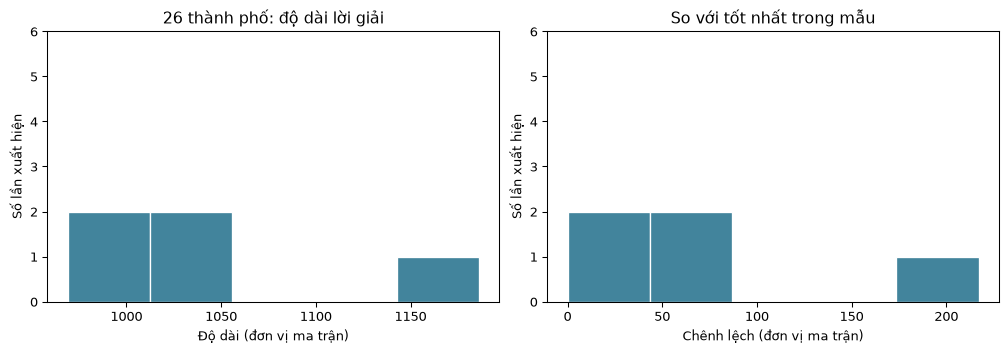

In [12]:
problem = load_matrix(ROOT/'data'/'26Cities-937.txt')
runs = [checked_solve(problem, replace(BASE, seed=seed)) for seed in SEEDS]
runs_by_dataset[problem.name] = runs
summary = summarize(runs)
if problem.known_optimum is not None:
    reference, reference_label = problem.known_optimum, 'Nghiệm tối ưu đã xác minh từ dữ liệu'
elif problem.dimension <= 6:
    n, matrix = problem.dimension, problem.distance_matrix
    reference = min(fsum(matrix[route[i]][route[(i + 1) % n]] for i in range(n))
                    for tail in permutations(range(1, n)) for route in [(0, *tail)])
    reference_label = 'Tối ưu kiểm chứng bằng liệt kê'
else:
    reference, reference_label = summary['best'], 'Tốt nhất quan sát trong mẫu'
deviations = [r.best_distance - reference for r in runs]
assert all(value >= -1e-9 for value in deviations)
summary.update(n=problem.dimension, reference=reference, reference_label=reference_label,
               deviation_mean=statistics.mean(deviations),
               relative_deviation=100 * statistics.mean(deviations) / reference if reference > 0 else None)
distribution_summary[problem.name] = summary
references[problem.name] = dict(value=reference, source=reference_label)
show_table(['Số lần', 'Tốt nhất', 'Trung bình', 'Kém nhất', 'Độ lệch chuẩn', 'Đánh giá min–max', 'Thời gian TB (s)'],
           [[len(runs), f"{summary['best']:g}", f"{summary['mean']:.2f}", f"{summary['worst']:g}",
             f"{summary['std']:.2f}", f"{summary['eval_min']}–{summary['eval_max']}", f"{summary['seconds']:.4f}"]])
print('Mốc:', reference_label, '=', reference, '| Trạng thái:', summary['reasons'])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), layout='constrained')
frequency_plot(axes[0], [r.best_distance for r in runs], 'Độ dài (đơn vị ma trận)', '26 thành phố: độ dài lời giải')
frequency_plot(axes[1], deviations, 'Chênh lệch (đơn vị ma trận)', 'So với tốt nhất trong mẫu' if reference_label == 'Tốt nhất quan sát trong mẫu' else 'So với tối ưu đã kiểm chứng')
plt.show(); plt.close(fig)

In [13]:
same_count = sum(isclose(r.best_distance, reference, abs_tol=1e-9) for r in runs)
spread_text = ('Các lần chạy cho cùng độ dài trong mẫu này.' if summary['std'] == 0 else
               'Các lần chạy có độ dài khác nhau, nên một lời giải riêng lẻ không mô tả đủ kết quả.')
display(Markdown(f"**Nhận xét.** Bài {problem.dimension} thành phố có độ dài từ {summary['best']:g} "
    f"đến {summary['worst']:g}, trung bình {summary['mean']:.2f}, độ lệch chuẩn {summary['std']:.2f}. "
    + spread_text + f" Chênh lệch trung bình so với mốc **{reference_label.lower()}** là "
    f"{summary['deviation_mean']:.2f}; có {same_count}/{len(runs)} lần bằng mốc. "
    + ('Với bài nhỏ đã liệt kê, đây là đối chiếu với nghiệm tối ưu của đúng ma trận đang dùng. '
       if 'liệt kê' in reference_label else
       'Với mốc tốt nhất quan sát, số lần bằng mốc không phải xác suất tìm nghiệm tối ưu. '
       if reference_label == 'Tốt nhất quan sát trong mẫu' else
       'Kết quả dùng nguồn optimum được gắn trong TSPProblem. ')
    + 'Các seed đã khai báo được giữ đầy đủ; mẫu ít không đủ để suy ra mức ổn định trên mọi bài toán.'))

**Nhận xét.** Bài 26 thành phố có độ dài từ 969 đến 1186, trung bình 1046.00, độ lệch chuẩn 82.85. Các lần chạy có độ dài khác nhau, nên một lời giải riêng lẻ không mô tả đủ kết quả. Chênh lệch trung bình so với mốc **tốt nhất quan sát trong mẫu** là 77.00; có 1/5 lần bằng mốc. Với mốc tốt nhất quan sát, số lần bằng mốc không phải xác suất tìm nghiệm tối ưu. Các seed đã khai báo được giữ đầy đủ; mẫu ít không đủ để suy ra mức ổn định trên mọi bài toán.

### Trường hợp 42 thành phố

Ma trận `42Cities-699.txt` có 42 hàng và 42 cột, mô tả chi phí giữa các thành phố. Chúng tôi chạy cùng cấu hình đã công bố và giữ tất cả seed để xem kết quả có tập trung hay phân tán. Với bài này chưa có nghiệm tối ưu được xác minh; mốc sẽ là tour ngắn nhất trong mẫu của chính dataset này, không lấy số trong tên file.

Bảng cho biết tốt nhất, trung bình, kém nhất, độ lệch chuẩn và số đánh giá thực tế. Hai hình đặt cạnh nhau lần lượt là phân bố độ dài và phân bố chênh lệch so với mốc được ghi trong tiêu đề. Giá trị 0 ở hình bên phải có nghĩa là bằng mốc đó; chỉ với mốc tối ưu đã kiểm chứng mới được hiểu là đạt tối ưu. Nhận xét sau hình dùng kết quả của toàn bộ seed, không dựa vào run riêng lẻ.

| Số lần | Tốt nhất | Trung bình | Kém nhất | Độ lệch chuẩn | Đánh giá min–max | Thời gian TB (s) |
| --- | --- | --- | --- | --- | --- | --- |
| 5 | 1102 | 1151.60 | 1211 | 49.75 | 4000–4000 | 0.1638 |

Mốc: Tốt nhất quan sát trong mẫu = 1102.0 | Trạng thái: {'MAX_EVALUATIONS': 5}


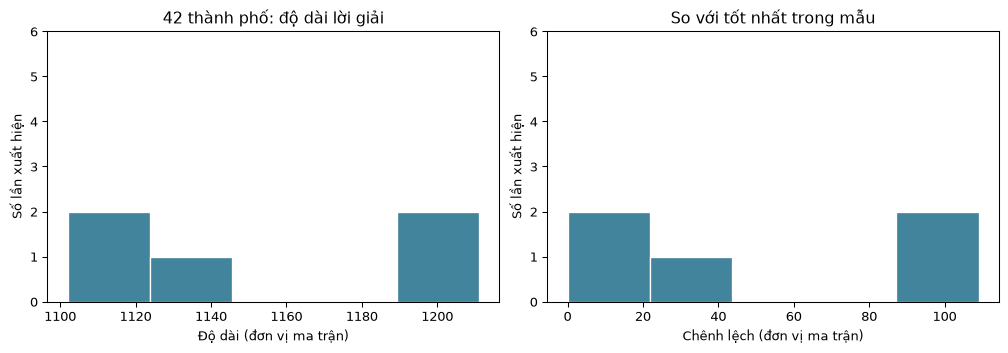

In [14]:
problem = load_matrix(ROOT/'data'/'42Cities-699.txt')
runs = [checked_solve(problem, replace(BASE, seed=seed)) for seed in SEEDS]
runs_by_dataset[problem.name] = runs
summary = summarize(runs)
if problem.known_optimum is not None:
    reference, reference_label = problem.known_optimum, 'Nghiệm tối ưu đã xác minh từ dữ liệu'
elif problem.dimension <= 6:
    n, matrix = problem.dimension, problem.distance_matrix
    reference = min(fsum(matrix[route[i]][route[(i + 1) % n]] for i in range(n))
                    for tail in permutations(range(1, n)) for route in [(0, *tail)])
    reference_label = 'Tối ưu kiểm chứng bằng liệt kê'
else:
    reference, reference_label = summary['best'], 'Tốt nhất quan sát trong mẫu'
deviations = [r.best_distance - reference for r in runs]
assert all(value >= -1e-9 for value in deviations)
summary.update(n=problem.dimension, reference=reference, reference_label=reference_label,
               deviation_mean=statistics.mean(deviations),
               relative_deviation=100 * statistics.mean(deviations) / reference if reference > 0 else None)
distribution_summary[problem.name] = summary
references[problem.name] = dict(value=reference, source=reference_label)
show_table(['Số lần', 'Tốt nhất', 'Trung bình', 'Kém nhất', 'Độ lệch chuẩn', 'Đánh giá min–max', 'Thời gian TB (s)'],
           [[len(runs), f"{summary['best']:g}", f"{summary['mean']:.2f}", f"{summary['worst']:g}",
             f"{summary['std']:.2f}", f"{summary['eval_min']}–{summary['eval_max']}", f"{summary['seconds']:.4f}"]])
print('Mốc:', reference_label, '=', reference, '| Trạng thái:', summary['reasons'])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), layout='constrained')
frequency_plot(axes[0], [r.best_distance for r in runs], 'Độ dài (đơn vị ma trận)', '42 thành phố: độ dài lời giải')
frequency_plot(axes[1], deviations, 'Chênh lệch (đơn vị ma trận)', 'So với tốt nhất trong mẫu' if reference_label == 'Tốt nhất quan sát trong mẫu' else 'So với tối ưu đã kiểm chứng')
plt.show(); plt.close(fig)

In [15]:
same_count = sum(isclose(r.best_distance, reference, abs_tol=1e-9) for r in runs)
spread_text = ('Các lần chạy cho cùng độ dài trong mẫu này.' if summary['std'] == 0 else
               'Các lần chạy có độ dài khác nhau, nên một lời giải riêng lẻ không mô tả đủ kết quả.')
display(Markdown(f"**Nhận xét.** Bài {problem.dimension} thành phố có độ dài từ {summary['best']:g} "
    f"đến {summary['worst']:g}, trung bình {summary['mean']:.2f}, độ lệch chuẩn {summary['std']:.2f}. "
    + spread_text + f" Chênh lệch trung bình so với mốc **{reference_label.lower()}** là "
    f"{summary['deviation_mean']:.2f}; có {same_count}/{len(runs)} lần bằng mốc. "
    + ('Với bài nhỏ đã liệt kê, đây là đối chiếu với nghiệm tối ưu của đúng ma trận đang dùng. '
       if 'liệt kê' in reference_label else
       'Với mốc tốt nhất quan sát, số lần bằng mốc không phải xác suất tìm nghiệm tối ưu. '
       if reference_label == 'Tốt nhất quan sát trong mẫu' else
       'Kết quả dùng nguồn optimum được gắn trong TSPProblem. ')
    + 'Các seed đã khai báo được giữ đầy đủ; mẫu ít không đủ để suy ra mức ổn định trên mọi bài toán.'))

**Nhận xét.** Bài 42 thành phố có độ dài từ 1102 đến 1211, trung bình 1151.60, độ lệch chuẩn 49.75. Các lần chạy có độ dài khác nhau, nên một lời giải riêng lẻ không mô tả đủ kết quả. Chênh lệch trung bình so với mốc **tốt nhất quan sát trong mẫu** là 49.60; có 1/5 lần bằng mốc. Với mốc tốt nhất quan sát, số lần bằng mốc không phải xác suất tìm nghiệm tối ưu. Các seed đã khai báo được giữ đầy đủ; mẫu ít không đủ để suy ra mức ổn định trên mọi bài toán.

### Trường hợp 48 thành phố

Ma trận `48Cities-33523.txt` có 48 hàng và 48 cột, mô tả chi phí giữa các thành phố. Chúng tôi chạy cùng cấu hình đã công bố và giữ tất cả seed để xem kết quả có tập trung hay phân tán. Với bài này chưa có nghiệm tối ưu được xác minh; mốc sẽ là tour ngắn nhất trong mẫu của chính dataset này, không lấy số trong tên file.

Bảng cho biết tốt nhất, trung bình, kém nhất, độ lệch chuẩn và số đánh giá thực tế. Hai hình đặt cạnh nhau lần lượt là phân bố độ dài và phân bố chênh lệch so với mốc được ghi trong tiêu đề. Giá trị 0 ở hình bên phải có nghĩa là bằng mốc đó; chỉ với mốc tối ưu đã kiểm chứng mới được hiểu là đạt tối ưu. Nhận xét sau hình dùng kết quả của toàn bộ seed, không dựa vào run riêng lẻ.

| Số lần | Tốt nhất | Trung bình | Kém nhất | Độ lệch chuẩn | Đánh giá min–max | Thời gian TB (s) |
| --- | --- | --- | --- | --- | --- | --- |
| 5 | 51215 | 55404.60 | 59638 | 3031.79 | 4000–4000 | 0.1568 |

Mốc: Tốt nhất quan sát trong mẫu = 51215.0 | Trạng thái: {'MAX_EVALUATIONS': 5}


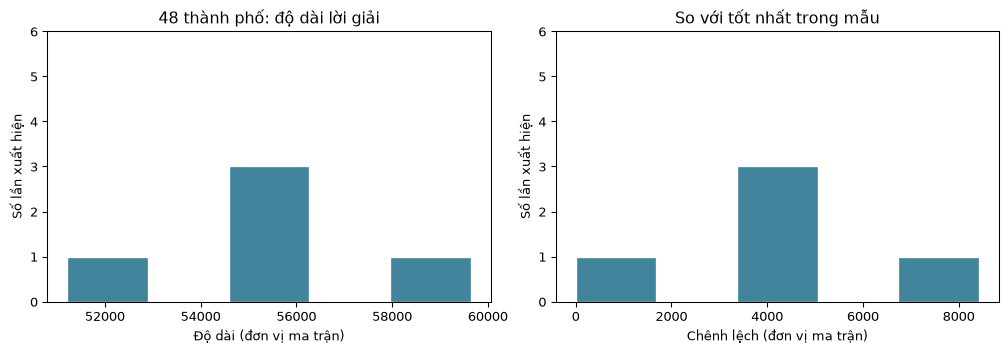

In [16]:
problem = load_matrix(ROOT/'data'/'48Cities-33523.txt')
runs = [checked_solve(problem, replace(BASE, seed=seed)) for seed in SEEDS]
runs_by_dataset[problem.name] = runs
summary = summarize(runs)
if problem.known_optimum is not None:
    reference, reference_label = problem.known_optimum, 'Nghiệm tối ưu đã xác minh từ dữ liệu'
elif problem.dimension <= 6:
    n, matrix = problem.dimension, problem.distance_matrix
    reference = min(fsum(matrix[route[i]][route[(i + 1) % n]] for i in range(n))
                    for tail in permutations(range(1, n)) for route in [(0, *tail)])
    reference_label = 'Tối ưu kiểm chứng bằng liệt kê'
else:
    reference, reference_label = summary['best'], 'Tốt nhất quan sát trong mẫu'
deviations = [r.best_distance - reference for r in runs]
assert all(value >= -1e-9 for value in deviations)
summary.update(n=problem.dimension, reference=reference, reference_label=reference_label,
               deviation_mean=statistics.mean(deviations),
               relative_deviation=100 * statistics.mean(deviations) / reference if reference > 0 else None)
distribution_summary[problem.name] = summary
references[problem.name] = dict(value=reference, source=reference_label)
show_table(['Số lần', 'Tốt nhất', 'Trung bình', 'Kém nhất', 'Độ lệch chuẩn', 'Đánh giá min–max', 'Thời gian TB (s)'],
           [[len(runs), f"{summary['best']:g}", f"{summary['mean']:.2f}", f"{summary['worst']:g}",
             f"{summary['std']:.2f}", f"{summary['eval_min']}–{summary['eval_max']}", f"{summary['seconds']:.4f}"]])
print('Mốc:', reference_label, '=', reference, '| Trạng thái:', summary['reasons'])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), layout='constrained')
frequency_plot(axes[0], [r.best_distance for r in runs], 'Độ dài (đơn vị ma trận)', '48 thành phố: độ dài lời giải')
frequency_plot(axes[1], deviations, 'Chênh lệch (đơn vị ma trận)', 'So với tốt nhất trong mẫu' if reference_label == 'Tốt nhất quan sát trong mẫu' else 'So với tối ưu đã kiểm chứng')
plt.show(); plt.close(fig)

In [17]:
same_count = sum(isclose(r.best_distance, reference, abs_tol=1e-9) for r in runs)
spread_text = ('Các lần chạy cho cùng độ dài trong mẫu này.' if summary['std'] == 0 else
               'Các lần chạy có độ dài khác nhau, nên một lời giải riêng lẻ không mô tả đủ kết quả.')
display(Markdown(f"**Nhận xét.** Bài {problem.dimension} thành phố có độ dài từ {summary['best']:g} "
    f"đến {summary['worst']:g}, trung bình {summary['mean']:.2f}, độ lệch chuẩn {summary['std']:.2f}. "
    + spread_text + f" Chênh lệch trung bình so với mốc **{reference_label.lower()}** là "
    f"{summary['deviation_mean']:.2f}; có {same_count}/{len(runs)} lần bằng mốc. "
    + ('Với bài nhỏ đã liệt kê, đây là đối chiếu với nghiệm tối ưu của đúng ma trận đang dùng. '
       if 'liệt kê' in reference_label else
       'Với mốc tốt nhất quan sát, số lần bằng mốc không phải xác suất tìm nghiệm tối ưu. '
       if reference_label == 'Tốt nhất quan sát trong mẫu' else
       'Kết quả dùng nguồn optimum được gắn trong TSPProblem. ')
    + 'Các seed đã khai báo được giữ đầy đủ; mẫu ít không đủ để suy ra mức ổn định trên mọi bài toán.'))

**Nhận xét.** Bài 48 thành phố có độ dài từ 51215 đến 59638, trung bình 55404.60, độ lệch chuẩn 3031.79. Các lần chạy có độ dài khác nhau, nên một lời giải riêng lẻ không mô tả đủ kết quả. Chênh lệch trung bình so với mốc **tốt nhất quan sát trong mẫu** là 4189.60; có 1/5 lần bằng mốc. Với mốc tốt nhất quan sát, số lần bằng mốc không phải xác suất tìm nghiệm tối ưu. Các seed đã khai báo được giữ đầy đủ; mẫu ít không đủ để suy ra mức ổn định trên mọi bài toán.

## Tổng hợp mức độ phân tán giữa các bộ dữ liệu

Bảng sau đặt kết quả bảy bài cạnh nhau nhưng không đánh đồng đơn vị chi phí giữa các bài. Cột chênh lệch tương đối được tính bằng `100 × (trung bình − mốc)/mốc` khi mốc dương. Nhãn nguồn mốc cho biết đó là nghiệm tối ưu được kiểm chứng hay chỉ là tốt nhất trong mẫu. Biểu đồ dùng đại lượng này để nhìn độ phân tán tương đối, không gọi mọi cột là khoảng cách tới tối ưu.

| Thành phố | Số lần | Tốt nhất | Trung bình | Kém nhất | Độ lệch chuẩn | Nguồn mốc | Chênh lệch TB (%) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 3 | 5 | 6 | 6.00 | 6 | 0.00 | Tối ưu kiểm chứng bằng liệt kê | 0.00 |
| 4 | 5 | 189 | 189.00 | 189 | 0.00 | Tối ưu kiểm chứng bằng liệt kê | 0.00 |
| 6 | 5 | 1248 | 1248.00 | 1248 | 0.00 | Tối ưu kiểm chứng bằng liệt kê | 0.00 |
| 15 | 5 | 1194 | 1200.20 | 1225 | 13.86 | Tốt nhất quan sát trong mẫu | 0.52 |
| 26 | 5 | 969 | 1046.00 | 1186 | 82.85 | Tốt nhất quan sát trong mẫu | 7.95 |
| 42 | 5 | 1102 | 1151.60 | 1211 | 49.75 | Tốt nhất quan sát trong mẫu | 4.50 |
| 48 | 5 | 51215 | 55404.60 | 59638 | 3031.79 | Tốt nhất quan sát trong mẫu | 8.18 |

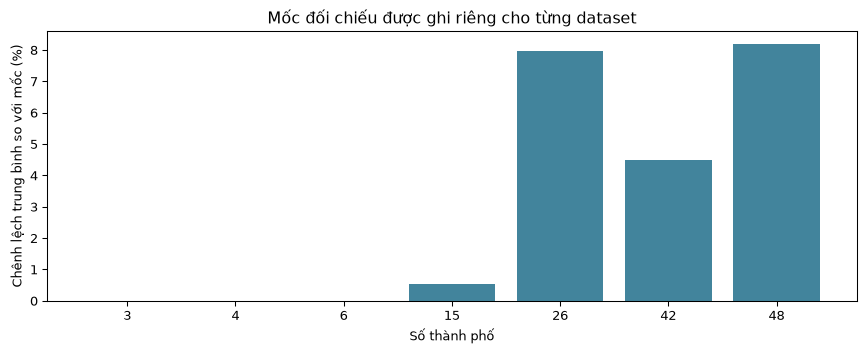

**Kết luận Experiment 3.** Trong lần chạy này, 3 thành phố: độ lệch chuẩn 0.00; 4 thành phố: độ lệch chuẩn 0.00; 6 thành phố: độ lệch chuẩn 0.00; 15 thành phố: độ lệch chuẩn 13.86; 26 thành phố: độ lệch chuẩn 82.85; 42 thành phố: độ lệch chuẩn 49.75; 48 thành phố: độ lệch chuẩn 3031.79. Chúng tôi quan sát được mức phân tán cụ thể ở từng bài dưới cùng số phép đánh giá. Bài có độ lệch chuẩn tuyệt đối lớn chưa chắc kém ổn định hơn theo tỷ lệ vì thang chi phí khác nhau. Mỗi bài chỉ có 5 seed; histogram giúp mô tả mẫu, chưa đủ để khẳng định quy mô lớn luôn làm GA kém ổn định. Các mốc tốt nhất quan sát có thể thay đổi khi bổ sung seed; không được diễn giải chúng như nghiệm tối ưu đã chứng minh.

In [18]:
show_table(['Thành phố', 'Số lần', 'Tốt nhất', 'Trung bình', 'Kém nhất', 'Độ lệch chuẩn',
            'Nguồn mốc', 'Chênh lệch TB (%)'],
           [[s['n'], len(SEEDS), f"{s['best']:g}", f"{s['mean']:.2f}", f"{s['worst']:g}",
             f"{s['std']:.2f}", s['reference_label'],
             f"{s['relative_deviation']:.2f}" if s['relative_deviation'] is not None else 'Không xác định']
            for s in distribution_summary.values()])
fig, ax = plt.subplots(figsize=(9, 3.6), layout='constrained')
defined = [s for s in distribution_summary.values() if s['relative_deviation'] is not None]
ax.bar([str(s['n']) for s in defined], [s['relative_deviation'] for s in defined], color='#42849c')
ax.set(xlabel='Số thành phố', ylabel='Chênh lệch trung bình so với mốc (%)', title='Mốc đối chiếu được ghi riêng cho từng dataset')
plt.show(); plt.close(fig)
range_text = '; '.join(f"{s['n']} thành phố: độ lệch chuẩn {s['std']:.2f}" for s in distribution_summary.values())
display(Markdown('**Kết luận Experiment 3.** Trong lần chạy này, ' + range_text + '. '
    'Chúng tôi quan sát được mức phân tán cụ thể ở từng bài dưới cùng số phép đánh giá. '
    'Bài có độ lệch chuẩn tuyệt đối lớn chưa chắc kém ổn định hơn theo tỷ lệ vì thang chi phí khác nhau. '
    f'Mỗi bài chỉ có {len(SEEDS)} seed; histogram giúp mô tả mẫu, chưa đủ để khẳng định quy mô lớn luôn làm GA kém ổn định. '
    'Các mốc tốt nhất quan sát có thể thay đổi khi bổ sung seed; không được diễn giải chúng như nghiệm tối ưu đã chứng minh.'))
repro_problem = load_matrix(ROOT/'data/48Cities-33523.txt')
repro_result = runs_by_dataset[repro_problem.name][0]

## Kiểm tra tái lập và tổng kết lần chạy

Chúng tôi chạy lại đúng cấu hình và seed của một kết quả đã có. Tour, độ dài, số lần đánh giá và toàn bộ lịch sử số phải khớp; thời gian được loại khỏi phép so sánh vì phụ thuộc môi trường. Lần kiểm tra này được đếm riêng, không đưa thêm vào thống kê nhiều seed.

In [19]:
repeat = checked_solve(repro_problem, GAConfig(**repro_result.config_snapshot))
assert numeric_signature(repeat) == numeric_signature(repro_result)
expected_main_runs = 7 * len(SEEDS)
assert RUN_COUNT == expected_main_runs + 1
NOTEBOOK_REPORT = dict(notebook='Experiment 3', mode=MODE, seeds=SEEDS,
                       experiment_runs=expected_main_runs, verification_runs=1,
                       total_runs=RUN_COUNT, solver_seconds=SOLVER_SECONDS,
                       wall_seconds=perf_counter() - SESSION_START,
                       summaries=distribution_summary)
display(Markdown(f"Đã hoàn tất **{expected_main_runs} lần thực nghiệm** và **1 lần kiểm tra tái lập**, "
    f"tổng {RUN_COUNT} lần gọi GA. Thời gian trong solver là {SOLVER_SECONDS:.3f} giây. "
    'Mọi tour đã qua kiểm tra chi phí và hoán vị; không có lần lỗi nào bị bỏ khỏi thống kê. '
    'Các kết quả khi dừng sớm vẫn được giữ cùng lý do dừng trong bảng.'))

Đã hoàn tất **35 lần thực nghiệm** và **1 lần kiểm tra tái lập**, tổng 36 lần gọi GA. Thời gian trong solver là 3.544 giây. Mọi tour đã qua kiểm tra chi phí và hoán vị; không có lần lỗi nào bị bỏ khỏi thống kê. Các kết quả khi dừng sớm vẫn được giữ cùng lý do dừng trong bảng.